In [1]:
import os

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from skimage import filters
from scipy import stats
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from copy import copy

from tqdm import tqdm

In [24]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [22]:
def mesh2pcd(mesh):
    mesh_pcd = o3d.geometry.PointCloud()
    mesh_pcd.points = mesh.vertices
    mesh_pcd.colors = mesh.vertex_colors
    mesh_pcd.normals = mesh.vertex_normals
    
    return mesh_pcd

def project_points_on_vector(points, vector):
    """
    把点投影到给定向量上
    输入：points: nx3的三维点
         vector: 1x3的向量
    输出：投影后的点(在空间中的位置)
    """
    v_norm = np.sqrt(sum(vector**2))
    
    return (np.dot(points, vector.reshape(3,1))/v_norm**2)*vector


def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = project_points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
    kmeans.fit(rgb)

    ## the z axis points of each class
    z0 = pcd_on_z_unit[kmeans.labels_ == 0]
    z1 = pcd_on_z_unit[kmeans.labels_ == 1]
    z0_mean = z0.mean()
    z1_mean = z1.mean()

    # find out which is the crown class
    ## calculate the direction
    pmax = pcd_on_z_unit.max()
    pmin = pcd_on_z_unit.min()
    pmid = (pmax + pmin) / 2
    pmean = pcd_on_z_unit.mean()

    if pmean < pmid:
        # The crown is in the -z direction (points KDE line)
        #
        # |        pmean
        # |       . |    pmid
        # |     .   |  . ||
        # |   .     |    ||  .  
        # | .       |    ||       ^   .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] #* -1
        if z0_mean < z1_mean:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0
        else:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
    else:
        # The crown is in the +z direction (points KDE line)
        #
        # |                 pmean
        # |            pmid   |  .
        # |             ||  . |    .
        # |           . ||    |      .
        # | .     ^     ||    |        .
        # o-------------------------------> +z
        
        # vz is the crown Z direction vertex
        vz = obb.R[:,main_idx] * -1
        if z0_mean < z1_mean:
            # print('z1 is crown')
            crown_bool_idx = kmeans.labels_ == 1
        else:
            # print('z0 is crown')
            crown_bool_idx = kmeans.labels_ == 0

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = head_pcd.select_by_index(crown_int_idx)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_statistical_outlier(denoise_count, denoise_radius)
    crown_pcd_denoised, keeped_int_idx = remove_dbscan_outlier(crown_pcd, denoise_count, denoise_radius, show_log)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    if show_log:
        kde0 = stats.gaussian_kde(z0)
        xx0 = np.linspace(pmin, pmax, 1000)
        yy0 = kde0(xx0)

        kde1 = stats.gaussian_kde(z1)
        xx1 = np.linspace(pmin, pmax, 1000)
        yy1 = kde1(xx1)

        fig, ax = plt.subplots(1,1)
        ax.plot(xx0, yy0,color='b', label='z0')
        ax.plot(xx1, yy1,color='g', label='z1')

        ax.axvline(x=pmid, color='r', label="middle")

        ax.axvline(x=z0_mean, color='b', label="z0mean")
        ax.axvline(x=z1_mean, color='g',label="z1mean")

        plt.legend()
        plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx, vz


#====================

def remove_dbscan_outlier(pcd, min_points, eps, show_log=False):
    label = pcd.cluster_dbscan(eps=eps, min_points=min_points, print_progress=True)
    db_labels, db_count = np.unique(label, return_counts=True)

    if len(db_count) <= 2:  # already splited by [-1 ,0]
        plant_cluster_idx = [0]
    else:
        # calculate the cluster size as another reference
        characters = np.empty((len(db_count), 2))
        for i, (l, c) in enumerate(zip(db_labels, db_count)):
            idx_on_label = np.where(label==l)[0]
            pcd_on_label = pcd.select_by_index(idx_on_label)
            volume = _calculate_xyz_volume(pcd_on_label)

            characters[i-1, 0] = c
            characters[i-1, 1] = volume

        # print("charectors:\n",characters)
        # Kmeans cluster
        km = KMeans(n_clusters=2, n_init=10)
        km.fit(characters)

        class0 = characters[km.labels_ == 0, :]
        class1 = characters[km.labels_ == 1, :]

        # print("class0, class1\n", class0, '\n', class1)
        # find the class label with largest point clouds (plants)
        if class0.mean(axis=0)[0] > class1.mean(axis=0)[0]:
            plant_cluster_idx = np.where(km.labels_ == 0)[0]
        else:
            plant_cluster_idx = np.where(km.labels_ == 1)[0]

        if show_log: print(f"DBSCAN\nlabel - count\n{np.vstack([db_labels, db_count]).T}\nUse {plant_cluster_idx} as plants")
        plant_id = []
        for idx in plant_cluster_idx:
            # print(idx, label, np.where(np.array(label)==idx)[0])
            plant_id += np.where(np.array(label)==idx)[0].tolist()

        # print("plant_id\n", plant_id)

        return pcd.select_by_index(plant_id), plant_id

def _calculate_xyz_volume(pcd):
    pcd_xyz = np.asarray(pcd.points)

    x_len = pcd_xyz[:, 0].max() - pcd_xyz[:, 0].min()
    y_len = pcd_xyz[:, 1].max() - pcd_xyz[:, 1].min()
    z_len = pcd_xyz[:, 2].max() - pcd_xyz[:, 2].min()

    return x_len * y_len * z_len


# ==============================
def rotate_to_z(crown_pcd, original_pcd, vz):
    obb = crown_pcd.get_oriented_bounding_box()
    
    # find out the closest vector to orginal broccoli longest axis
    clamp_angle_sin = []
    angle_list = []
    for i in range(0, 3):
        angle = angle2(vz, obb.R[:, i])
        angle_list.append(angle)
        clamp_angle_sin.append(np.sin(np.deg2rad(angle)))

    main_idx = np.argmin(np.asarray(clamp_angle_sin))
    if angle_list[main_idx] < 90:
        main_direction = obb.R[:, main_idx] * -1
    else:
        main_direction = obb.R[:, main_idx]

    R = get_rotation_matrix(get_unit_vector(main_direction), (0,0,1))
    pcd_rotated = copy(original_pcd).rotate(R, center=obb.center)

    return pcd_rotated


def angle2(v1, v2):
    x=np.array(v1)
    y=np.array(v2)

    # 分别计算两个向量的模：
    module_x=np.sqrt(x.dot(x))
    module_y=np.sqrt(y.dot(y))

    # 计算两个向量的点积
    dot_value=x.dot(y)

    # 计算夹角的cos值：
    cos_theta=dot_value/(module_x*module_y)

    # 求得夹角（弧度制）：
    angle_radian=np.arccos(cos_theta)

    # 转换为角度值：
    angle_value=angle_radian*180/np.pi
    return angle_value

def get_unit_vector(v):
    return v / np.linalg.norm(v)

def get_rotation_matrix(a, b):
    v = np.cross(a, b)
    s = np.dot(a, b)
    vx = np.array([[0, -v[2], v[1]],
                   [v[2], 0, -v[0]],
                   [-v[1], v[0], 0]])
    R = np.identity(3) + vx + np.dot(vx, vx) * (1 / (1 + s))

    return R


# ===========================================
def draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, save_path, show=True):
    fig = plt.figure(figsize=(15, 10), dpi=300)
    ax1 = fig.add_subplot(231, projection='3d')
    ax2 = fig.add_subplot(232, projection='3d')
    ax3 = fig.add_subplot(233, projection='3d')
    ax4 = fig.add_subplot(234, projection='3d')
    ax5 = fig.add_subplot(235, projection='3d')
    ax6 = fig.add_subplot(236, projection='3d')

    for ax in [ax1, ax2, ax3]:
        ax.scatter(*xyz_o.T, c=rgb_o, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')

        ax.set_box_aspect((np.ptp(xyz_o[:,0]), np.ptp(xyz_o[:,1]), np.ptp(xyz_o[:,2])))

    for ax in [ax4, ax5, ax6]:
        ax.scatter(*xyz_r.T, c=rgb_r, marker='.', alpha=0.5, s=1)
        ax.set_xlabel('X')
        ax.set_ylabel('Y')
        ax.set_zlabel('Z')
        ax.set_box_aspect((np.ptp(xyz_r[:,0]), np.ptp(xyz_r[:,1]), np.ptp(xyz_r[:,2])))

    ax1.view_init(elev=0, azim=45)
    ax2.view_init(elev=0, azim=165)
    ax3.view_init(elev=0, azim=285)
    ax4.view_init(elev=0, azim=45)
    ax5.view_init(elev=0, azim=165)
    ax6.view_init(elev=0, azim=285)

    ax1.set_title('45 degree azim')
    ax2.set_title('165 degree azim')
    ax3.set_title('285 degree azim')

    plt.tight_layout()
    plt.savefig(save_path)
    if show:
        plt.show()
    else:
        plt.cla()
        plt.clf()
        del fig, ax1, ax2, ax3, ax4, ax5, ax6

In [4]:
list(mesh_db.keys())[60]

'3-4'

/Users/hwang/anaconda/miniconda3/envs/lab/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


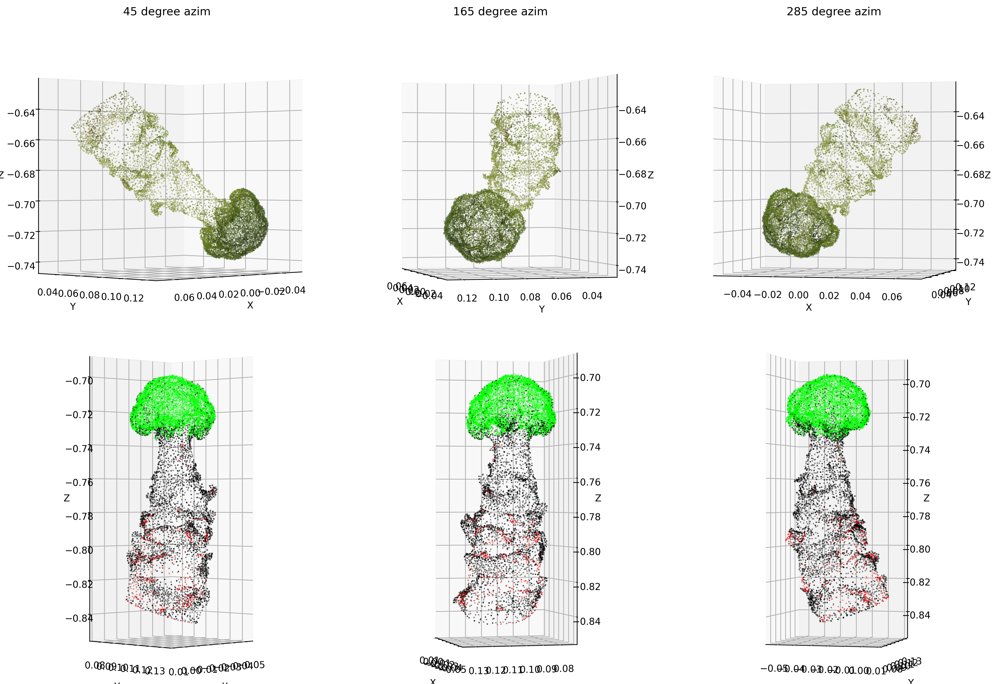

In [17]:
broccoli_id = '3-4'

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

batch process

/Users/hwang/anaconda/miniconda3/envs/lab/lib/python3.8/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


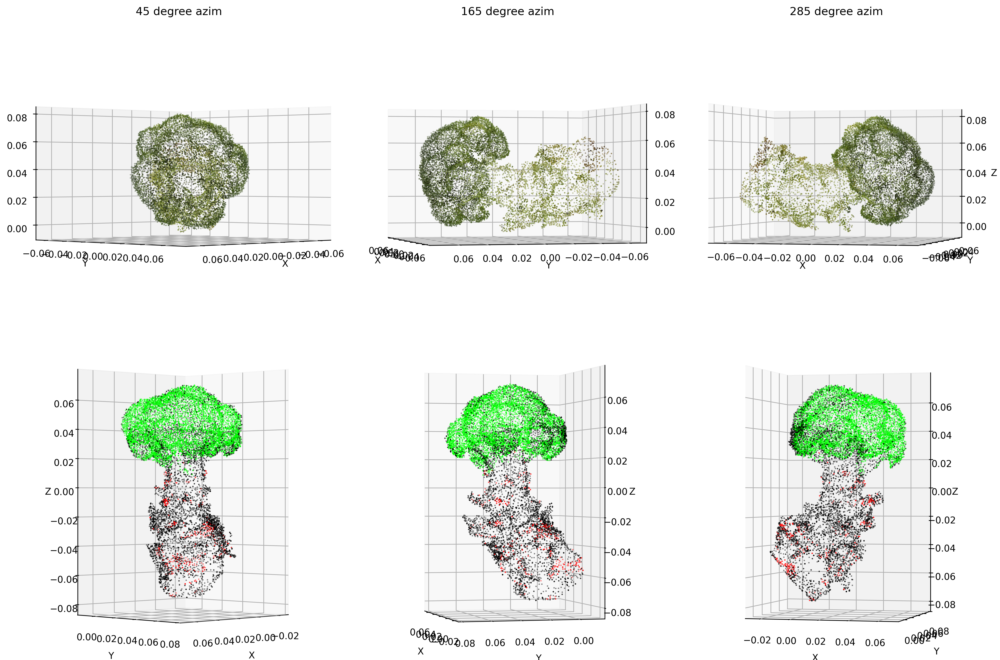

In [18]:
broccoli_id = '1-1'

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

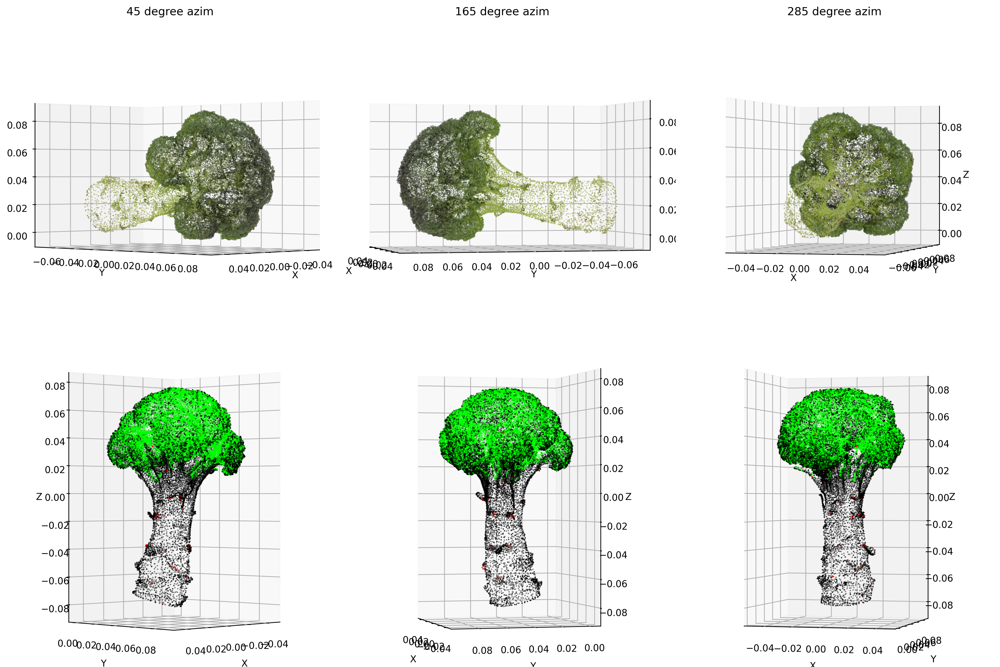

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

... (184 outputs left out)

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

<Figure size 4500x3000 with 0 Axes>

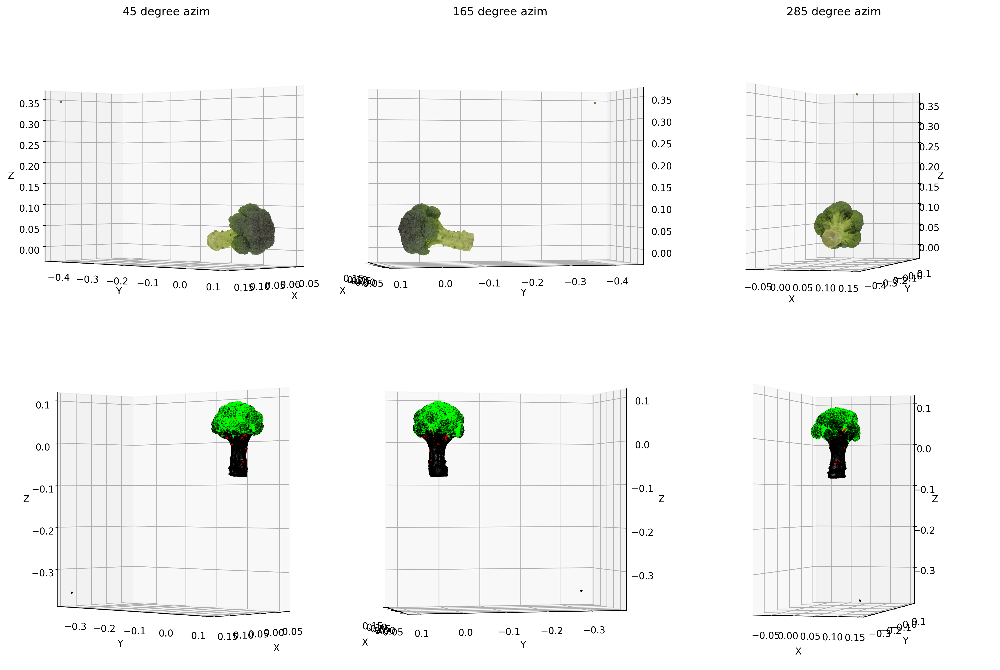

In [33]:
broccoli_id = '1-14'

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

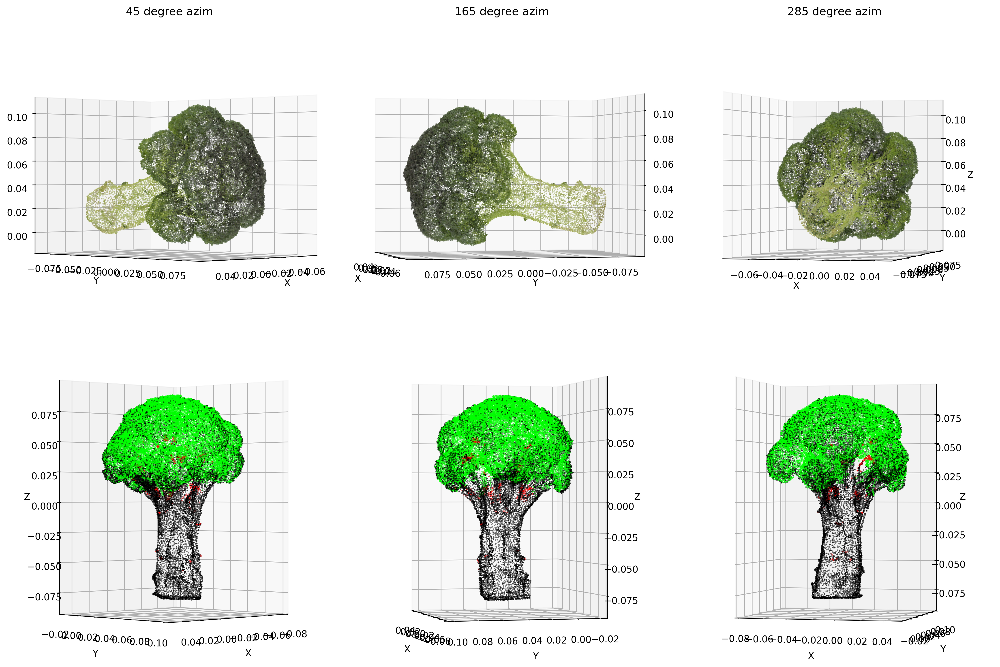

In [26]:
broccoli_id = '1-14_mal'

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

In [34]:
list(mesh_db.keys())[-1]

'1-14_mal.obj'

In [ ]:
broccoli_id = '1-14_mal'

def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(mesh_db[broccoli_id]))

crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{broccoli_id}_rot_seg.png")

In [27]:
import easyidp as idp

In [31]:
crown_idx = {}
for bro_id, bro_mesh in tqdm(mesh_db.items(), f"Processing Meshs"):
    def_test_pcd = mesh2pcd(o3d.io.read_triangle_mesh(bro_mesh))

    crown_pcd, crown_colored_pcd, crown_points_index, vz = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

    crown_idx[bro_id] = crown_points_index

    rotated_pcd = rotate_to_z(crown_pcd, def_test_pcd, vz)

    # draw figures
    xyz_o = np.asarray(def_test_pcd.points)
    rgb_o = np.asarray(def_test_pcd.colors)

    xyz_r = np.asarray(rotated_pcd.points)
    rgb_r = np.asarray(crown_colored_pcd.colors)

    draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, f"out/{bro_id}_rot_seg.png", show=False)

Processing Meshs:   9%|▊         | 17/195 [02:38<27:27,  9.26s/it]<ipython-input-22-1a52ebcc3991>:251: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(figsize=(15, 10), dpi=300)
Processing Meshs:  99%|█████████▉| 194/195 [31:19<00:09,  9.69s/it]

[Open3D WARNING] Read geometry::TriangleMesh failed: unknown file extension.


RuntimeError: QH6412 qhull input error (qh_initqhull_globals): expecting between 1 and 2147483631 points.  Got 0 3-d points

While executing:  | qhull Qt
Options selected for Qhull 2020.2.r 2020/08/31:
  run-id 1563604128  Qtriangulate  _maxoutside  0


In [32]:
idp.jsonfile.dict2json(crown_idx, "out/crown_index.json")